In [1]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [2]:
import zipfile
import os

# Ambil nama file ZIP yang diupload
zip_name = next(iter(uploaded))

# Lokasi ekstraksi
extract_path = "/content/chicken_dataset"

# Ekstrak file ZIP
with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset berhasil diekstrak!")
print("Lokasi:", extract_path)

Dataset berhasil diekstrak!
Lokasi: /content/chicken_dataset


In [5]:
import os

for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)
    indent = " " * 2 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}  {file}")

chicken_dataset/
  train_data.csv
  Train/
    cocci.1222.jpg
    salmo.1932.jpg
    pcrsalmo.263.jpg
    healthy.980.jpg
    healthy.1959.jpg


In [6]:
from collections import Counter

image_extensions = (".jpg", ".jpeg", ".png", ".webp")

image_files = []

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_files.append(
                os.path.join(root, file)
            )

print("Total gambar:", len(image_files))

print("\nJumlah gambar berdasarkan folder:")

folder_counts = Counter(
    os.path.basename(os.path.dirname(path))
    for path in image_files
)

for folder, jumlah in folder_counts.items():
    print(f"{folder}: {jumlah}")

Total gambar: 8067

Jumlah gambar berdasarkan folder:
Train: 8067


In [7]:
import pandas as pd
import os

# Lokasi file CSV
csv_path = os.path.join(extract_path, "train_data.csv")

# Membaca CSV
df = pd.read_csv(csv_path)

# Informasi dataset
print("Jumlah baris dan kolom:", df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\n5 data pertama:")
print(df.head())

print("\nJumlah data kosong:")
print(df.isnull().sum())

# Menampilkan jumlah data per kelas
label_columns = [
    col for col in df.columns
    if any(k in col.lower() for k in ["label", "class", "disease"])
]

if label_columns:
    label_col = label_columns[0]
    print("\nDistribusi kelas:")
    print(df[label_col].value_counts())
else:
    print("\nKolom label belum teridentifikasi.")

Jumlah baris dan kolom: (8067, 2)

Nama kolom:
['images', 'label']

5 data pertama:
           images               label
0  salmo.1558.jpg          Salmonella
1  cocci.1866.jpg         Coccidiosis
2   cocci.171.jpg         Coccidiosis
3  salmo.1484.jpg          Salmonella
4     ncd.100.jpg  New Castle Disease

Jumlah data kosong:
images    0
label     0
dtype: int64

Distribusi kelas:
label
Salmonella            2625
Coccidiosis           2476
Healthy               2404
New Castle Disease     562
Name: count, dtype: int64


In [8]:
import os

# Lokasi folder gambar
train_dir = os.path.join(extract_path, "Train")

# Menggabungkan nama file dengan lokasi folder
df["filepath"] = df["images"].apply(
    lambda x: os.path.join(train_dir, x)
)

# Periksa keberadaan file
df["exists"] = df["filepath"].apply(os.path.exists)

print("Total data CSV:", len(df))
print("Gambar ditemukan:", df["exists"].sum())
print("Gambar tidak ditemukan:", (~df["exists"]).sum())

# Periksa duplikat nama file
print("\nDuplikat nama file:",
      df["images"].duplicated().sum())

# Periksa nilai kosong
print("\nMissing Values:")
print(df[["images", "label"]].isnull().sum())

Total data CSV: 8067
Gambar ditemukan: 8067
Gambar tidak ditemukan: 0

Duplikat nama file: 0

Missing Values:
images    0
label     0
dtype: int64


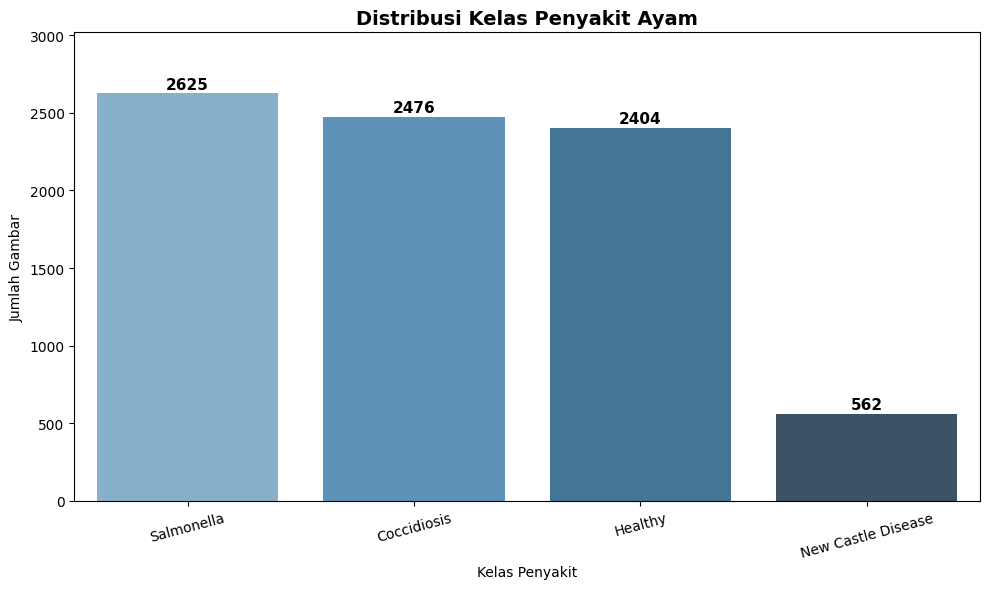

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Hitung jumlah gambar per kelas
class_counts = df["label"].value_counts()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette="Blues_d",
    legend=False
)

# Menambahkan jumlah gambar di atas setiap bar
for i, value in enumerate(class_counts.values):
    ax.text(
        i, value + 30,
        str(value),
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Distribusi Kelas Penyakit Ayam",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Kelas Penyakit")
plt.ylabel("Jumlah Gambar")
plt.ylim(0, max(class_counts.values) * 1.15)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

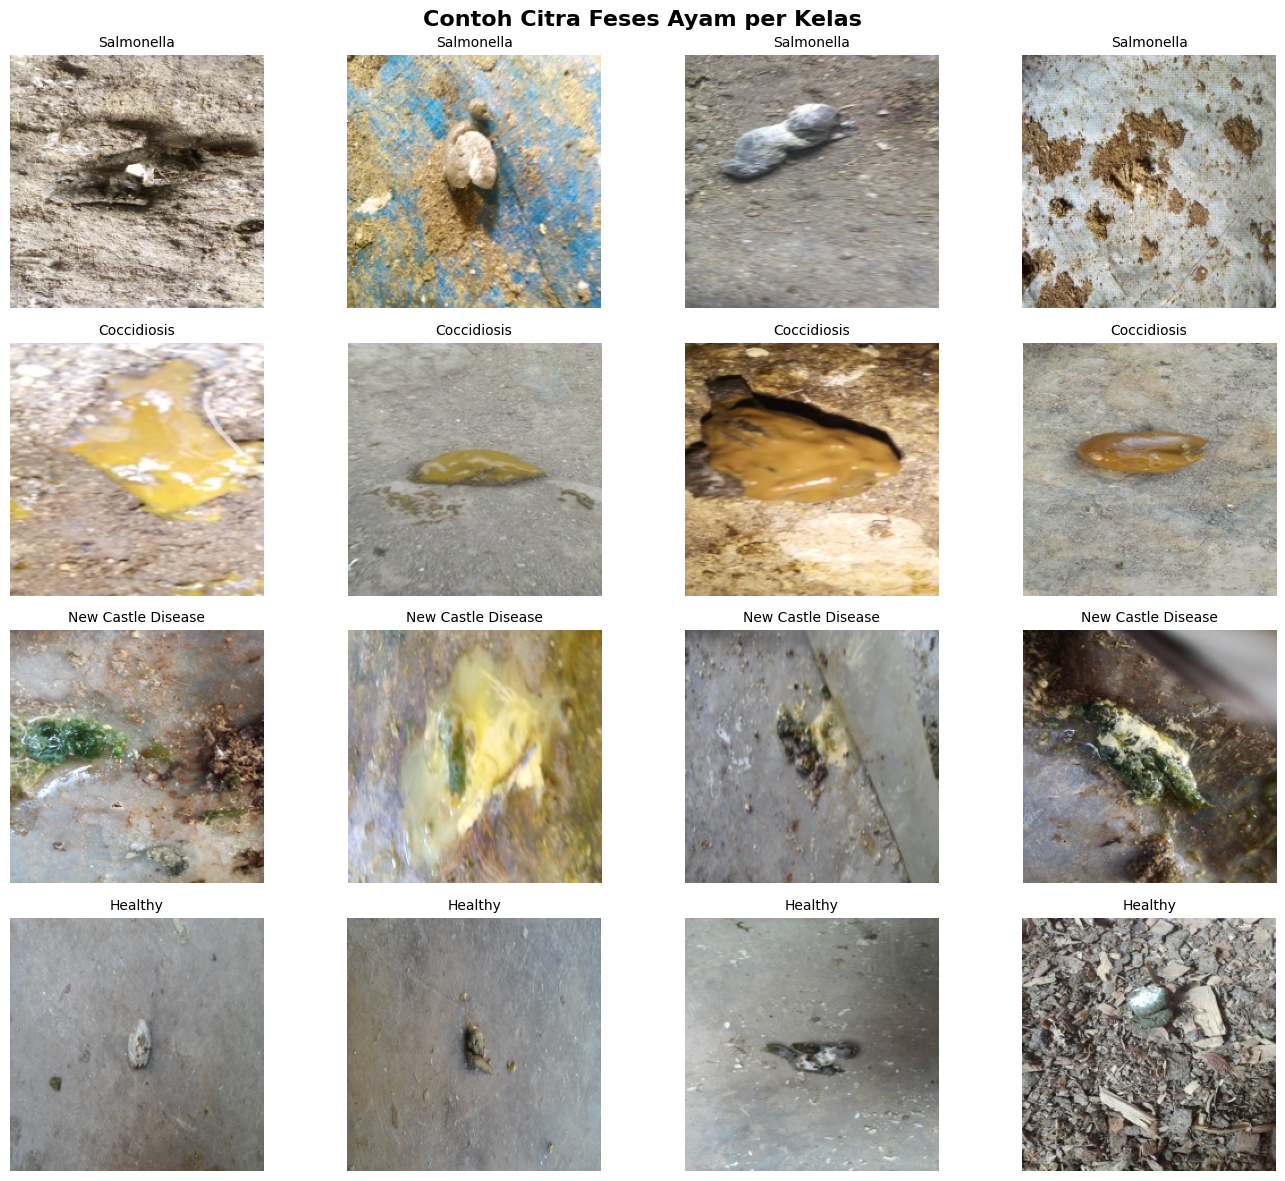

In [11]:
from PIL import Image
import matplotlib.pyplot as plt

classes = df["label"].unique()

fig, axes = plt.subplots(
    len(classes), 4,
    figsize=(14, 12)
)

for i, kelas in enumerate(classes):

    samples = df[
        (df["label"] == kelas) & (df["exists"])
    ].sample(n=4, random_state=42)

    for j, (_, row) in enumerate(samples.iterrows()):

        img = Image.open(row["filepath"])

        axes[i, j].imshow(img)
        axes[i, j].axis("off")

        axes[i, j].set_title(
            kelas,
            fontsize=10
        )

plt.suptitle(
    "Contoh Citra Feses Ayam per Kelas",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [12]:
from PIL import Image
from collections import Counter, defaultdict
import pandas as pd
import hashlib
import os

# Lokasi gambar
train_dir = os.path.join(extract_path, "Train")

image_info = []
corrupted_images = []
hash_groups = defaultdict(list)

for _, row in df.iterrows():
    img_path = os.path.join(train_dir, row["images"])

    try:
        with Image.open(img_path) as img:
            width, height = img.size
            mode = img.mode
            img.verify()

        # Hash untuk mendeteksi duplikat identik
        sha = hashlib.sha256()

        with open(img_path, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                sha.update(chunk)

        hash_groups[sha.hexdigest()].append(row["images"])

        image_info.append({
            "image": row["images"],
            "width": width,
            "height": height,
            "mode": mode
        })

    except Exception as e:
        corrupted_images.append((row["images"], str(e)))

# DataFrame hasil pemeriksaan
df_info = pd.DataFrame(image_info)

# Cek resolusi
resolution_counts = Counter(
    zip(df_info["width"], df_info["height"])
)

# Cek duplikat
duplicate_groups = [
    names for names in hash_groups.values()
    if len(names) > 1
]

print("=== HASIL PEMERIKSAAN DATASET ===")
print("Total gambar valid:", len(df_info))
print("Gambar rusak:", len(corrupted_images))
print("Jumlah grup duplikat identik:", len(duplicate_groups))
print("Total duplikat tambahan:",
      sum(len(g) - 1 for g in duplicate_groups))

print("\n=== FORMAT WARNA ===")
print(df_info["mode"].value_counts())

print("\n=== RESOLUSI GAMBAR ===")
for resolusi, jumlah in resolution_counts.most_common(10):
    print(f"{resolusi}: {jumlah} gambar")

print("\n=== CONTOH DUPLIKAT ===")
for group in duplicate_groups[:5]:
    print(group)

print("\n=== CONTOH GAMBAR RUSAK ===")
print(corrupted_images[:5])

=== HASIL PEMERIKSAAN DATASET ===
Total gambar valid: 8067
Gambar rusak: 0
Jumlah grup duplikat identik: 222
Total duplikat tambahan: 280

=== FORMAT WARNA ===
mode
RGB    8067
Name: count, dtype: int64

=== RESOLUSI GAMBAR ===
(224, 224): 8067 gambar

=== CONTOH DUPLIKAT ===
['cocci.1866.jpg', 'cocci.180.jpg']
['cocci.1923.jpg', 'cocci.2093.jpg']
['salmo.1702.jpg', 'salmo.93.jpg', 'salmo.546.jpg']
['cocci.1642.jpg', 'cocci.1892.jpg']
['cocci.1545.jpg', 'cocci.1414.jpg']

=== CONTOH GAMBAR RUSAK ===
[]


In [13]:
# Membuat pemetaan nama gambar dan hash
name_to_hash = {
    name: image_hash
    for image_hash, names in hash_groups.items()
    for name in names
}

# Salin dataframe asli
df_check = df.copy()

# Tambahkan hash untuk setiap gambar
df_check["image_hash"] = (
    df_check["images"].map(name_to_hash)
)

# Pastikan setiap gambar memiliki hash
print("Gambar tanpa hash:",
      df_check["image_hash"].isnull().sum())

# Periksa apakah gambar identik memiliki label berbeda
label_counts = (
    df_check.groupby("image_hash")["label"]
    .nunique()
)

conflict_hashes = label_counts[
    label_counts > 1
].index

print("\n=== PEMERIKSAAN DUPLIKAT ===")

print("Jumlah grup dengan konflik label:",
      len(conflict_hashes))

if len(conflict_hashes) > 0:
    print("\nGambar dengan konflik label:")

    display(
        df_check[
            df_check["image_hash"].isin(conflict_hashes)
        ][["images", "label", "image_hash"]]
    )

else:
    print("Tidak ditemukan konflik label.")

    # Hapus duplikat identik dari dataframe
    df_clean = df_check.drop_duplicates(
        subset="image_hash",
        keep="first"
    ).copy()

    df_clean = df_clean.reset_index(drop=True)

    print("\n=== HASIL DATA CLEANING ===")
    print("Data sebelum:", len(df))
    print("Data sesudah:", len(df_clean))
    print("Duplikat dihapus:",
          len(df) - len(df_clean))

    print("\nDistribusi kelas setelah cleaning:")
    print(df_clean["label"].value_counts())

Gambar tanpa hash: 0

=== PEMERIKSAAN DUPLIKAT ===
Jumlah grup dengan konflik label: 3

Gambar dengan konflik label:


,images,label,image_hash
410,pcrhealthy.83.jpg,Healthy,363c548640cb5eab4bd015b40e4a0785d4ff90c0d75679...
990,pcrhealthy.306.jpg,Healthy,b146fc4a279c459d864f8447449a9313be14c2b8cd3726...
3444,pcrsalmo.332.jpg,Salmonella,7f4270d218bb7ce43db261d88a7aaff78dabe457d5064f...
5544,pcrcocci.228.jpg,Coccidiosis,363c548640cb5eab4bd015b40e4a0785d4ff90c0d75679...
6477,pcrhealthy.153.jpg,Healthy,7f4270d218bb7ce43db261d88a7aaff78dabe457d5064f...
6974,pcrsalmo.202.jpg,Salmonella,b146fc4a279c459d864f8447449a9313be14c2b8cd3726...


In [14]:
# 1. Identifikasi grup gambar dengan konflik label
conflict_hashes = (
    df_check.groupby("image_hash")["label"]
    .nunique()
    .loc[lambda x: x > 1]
    .index
)

# 2. Hapus seluruh gambar yang memiliki konflik label
df_no_conflict = df_check[
    ~df_check["image_hash"].isin(conflict_hashes)
].copy()

# 3. Hapus gambar duplikat identik
df_clean = df_no_conflict.drop_duplicates(
    subset="image_hash",
    keep="first"
).copy()

df_clean = df_clean.reset_index(drop=True)

# 4. Periksa hasil pembersihan
print("=== HASIL FINAL DATA CLEANING ===")

print("Data awal:", len(df_check))

print("Gambar konflik dihapus:",
      len(df_check) - len(df_no_conflict))

print("Duplikat tambahan dihapus:",
      len(df_no_conflict) - len(df_clean))

print("Total gambar bersih:", len(df_clean))

print("\n=== DISTRIBUSI KELAS SETELAH CLEANING ===")
print(df_clean["label"].value_counts())

print("\n=== VALIDASI ===")
print("Duplikat tersisa:",
      df_clean["image_hash"].duplicated().sum())

print("Missing value:")
print(df_clean[["images", "label"]].isnull().sum())

=== HASIL FINAL DATA CLEANING ===
Data awal: 8067
Gambar konflik dihapus: 6
Duplikat tambahan dihapus: 277
Total gambar bersih: 7784

=== DISTRIBUSI KELAS SETELAH CLEANING ===
label
Salmonella            2481
Healthy               2399
Coccidiosis           2342
New Castle Disease     562
Name: count, dtype: int64

=== VALIDASI ===
Duplikat tersisa: 0
Missing value:
images    0
label     0
dtype: int64


In [6]:
import pandas as pd
import os
import hashlib

# Lokasi dataset
extract_path = "/content/chicken_dataset"
train_dir = os.path.join(extract_path, "Train")
csv_path = os.path.join(extract_path, "train_data.csv")

# Baca dataset asli
df = pd.read_csv(csv_path)

# Fungsi menghitung hash gambar
def get_image_hash(filename):
    path = os.path.join(train_dir, filename)

    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

# Tambahkan hash untuk setiap gambar
df["image_hash"] = df["images"].apply(get_image_hash)

print("=== DATA AWAL ===")
print("Total gambar:", len(df))

# 1. Cari konflik label
label_counts = (
    df.groupby("image_hash")["label"].nunique()
)

conflict_hashes = label_counts[
    label_counts > 1
].index

print("\nGrup konflik label:", len(conflict_hashes))

# 2. Hapus gambar dengan konflik label
df_no_conflict = df[
    ~df["image_hash"].isin(conflict_hashes)
].copy()

# 3. Hapus duplikat identik
df_clean = df_no_conflict.drop_duplicates(
    subset="image_hash",
    keep="first"
).reset_index(drop=True)

# 4. Tampilkan hasil
print("\n=== HASIL DATA CLEANING ===")

print("Data awal:", len(df))

print("Gambar konflik dihapus:",
      len(df) - len(df_no_conflict))

print("Duplikat tambahan dihapus:",
      len(df_no_conflict) - len(df_clean))

print("Total gambar bersih:", len(df_clean))

print("\nDistribusi kelas:")
print(df_clean["label"].value_counts())

# 5. Simpan dataset bersih
clean_csv_path = os.path.join(
    extract_path, "train_data_clean.csv"
)

df_clean[["images", "label"]].to_csv(
    clean_csv_path,
    index=False
)

print("\nDataset bersih berhasil disimpan!")
print("Lokasi:", clean_csv_path)

# 6. Validasi
print("\n=== VALIDASI ===")
print("Duplikat tersisa:",
      df_clean["image_hash"].duplicated().sum())

=== DATA AWAL ===
Total gambar: 8067

Grup konflik label: 3

=== HASIL DATA CLEANING ===
Data awal: 8067
Gambar konflik dihapus: 6
Duplikat tambahan dihapus: 277
Total gambar bersih: 7784

Distribusi kelas:
label
Salmonella            2481
Healthy               2399
Coccidiosis           2342
New Castle Disease     562
Name: count, dtype: int64

Dataset bersih berhasil disimpan!
Lokasi: /content/chicken_dataset/train_data_clean.csv

=== VALIDASI ===
Duplikat tersisa: 0


In [5]:
import os
import pandas as pd
import hashlib
import zipfile
from pathlib import Path
from google.colab import files

# 1. Cari file CSV dataset
csv_files = list(Path("/content").rglob("train_data.csv"))

if not csv_files:
    print("Dataset tidak ditemukan. Mencari file ZIP...")

    zip_files = list(Path("/content").glob("*.zip"))

    if not zip_files:
        print("Silakan upload kembali file ZIP dataset.")
        uploaded = files.upload()

        zip_files = [
            Path("/content") / name
            for name in uploaded
            if name.lower().endswith(".zip")
        ]

    if not zip_files:
        raise FileNotFoundError("File ZIP tidak ditemukan.")

    extract_path = "/content/chicken_dataset"

    with zipfile.ZipFile(zip_files[0], "r") as z:
        z.extractall(extract_path)

    csv_files = list(Path("/content").rglob("train_data.csv"))

if not csv_files:
    raise FileNotFoundError("train_data.csv tidak ada dalam ZIP.")

# 2. Tentukan lokasi file secara otomatis
csv_path = csv_files[0]
train_dir = csv_path.parent / "Train"

print("CSV ditemukan:", csv_path)
print("Folder gambar:", train_dir)

# 3. Baca dataset
df = pd.read_csv(csv_path)

# 4. Hitung hash gambar
def get_hash(filename):
    path = train_dir / filename

    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

df["image_hash"] = df["images"].apply(get_hash)

# 5. Cari konflik label
conflict = (
    df.groupby("image_hash")["label"]
    .nunique()
)

conflict_hashes = conflict[conflict > 1].index

# 6. Hapus konflik label
df_no_conflict = df[
    ~df["image_hash"].isin(conflict_hashes)
].copy()

# 7. Hapus duplikat identik
df_clean = df_no_conflict.drop_duplicates(
    subset="image_hash"
).reset_index(drop=True)

# 8. Simpan dataset bersih
clean_csv_path = csv_path.parent / "train_data_clean.csv"

df_clean[["images", "label"]].to_csv(
    clean_csv_path,
    index=False
)

# 9. Tampilkan hasil
print("\n=== HASIL DATA CLEANING ===")
print("Data awal:", len(df))
print("Grup konflik label:", len(conflict_hashes))
print("Gambar konflik dihapus:", len(df) - len(df_no_conflict))
print("Duplikat tambahan dihapus:", len(df_no_conflict) - len(df_clean))
print("Total gambar bersih:", len(df_clean))

print("\nDistribusi kelas:")
print(df_clean["label"].value_counts())

print("\nCSV bersih tersimpan:", clean_csv_path)

Dataset tidak ditemukan. Mencari file ZIP...
Silakan upload kembali file ZIP dataset.


Saving archive.zip to archive.zip
CSV ditemukan: /content/chicken_dataset/train_data.csv
Folder gambar: /content/chicken_dataset/Train

=== HASIL DATA CLEANING ===
Data awal: 8067
Grup konflik label: 3
Gambar konflik dihapus: 6
Duplikat tambahan dihapus: 277
Total gambar bersih: 7784

Distribusi kelas:
label
Salmonella            2481
Healthy               2399
Coccidiosis           2342
New Castle Disease     562
Name: count, dtype: int64

CSV bersih tersimpan: /content/chicken_dataset/train_data_clean.csv


In [7]:
from sklearn.model_selection import train_test_split

# Split 70% training dan 30% sementara
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    stratify=df_clean["label"],
    random_state=42
)

# Split 15% validation dan 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

# Reset index
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("=== HASIL DATA SPLITTING ===")
print("Training   :", len(train_df))
print("Validation :", len(val_df))
print("Testing    :", len(test_df))

print("\nTotal data:",
      len(train_df) + len(val_df) + len(test_df))

=== HASIL DATA SPLITTING ===
Training   : 5448
Validation : 1168
Testing    : 1168

Total data: 7784


In [8]:
import pandas as pd

# Distribusi setiap kelas
distribution = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
})

distribution["Total"] = distribution.sum(axis=1)

print("=== DISTRIBUSI KELAS ===")
display(distribution)

# Cek duplikat identik antar dataset
train_hash = set(train_df["image_hash"])
val_hash = set(val_df["image_hash"])
test_hash = set(test_df["image_hash"])

print("\n=== DATA LEAKAGE CHECK ===")

print("Train vs Validation:",
      len(train_hash & val_hash))

print("Train vs Testing:",
      len(train_hash & test_hash))

print("Validation vs Testing:",
      len(val_hash & test_hash))

=== DISTRIBUSI KELAS ===


,Training,Validation,Testing,Total
label,,,,
Salmonella,1737,372,372,2481
Healthy,1679,360,360,2399
Coccidiosis,1639,351,352,2342
New Castle Disease,393,85,84,562



=== DATA LEAKAGE CHECK ===
Train vs Validation: 0
Train vs Testing: 0
Validation vs Testing: 0


In [9]:
import os
import zipfile
from google.colab import files

save_dir = "/content/chicken_dataset/splits"
os.makedirs(save_dir, exist_ok=True)

# Simpan ketiga dataset
train_df.to_csv(f"{save_dir}/train.csv", index=False)
val_df.to_csv(f"{save_dir}/validation.csv", index=False)
test_df.to_csv(f"{save_dir}/test.csv", index=False)

# Satukan CSV ke dalam ZIP
zip_output = "/content/chicken_splits.zip"

with zipfile.ZipFile(zip_output, "w") as z:
    for filename in ["train.csv", "validation.csv", "test.csv"]:
        z.write(
            f"{save_dir}/{filename}",
            arcname=filename
        )

print("Semua dataset berhasil disimpan!")

# Download ZIP ke laptop
files.download(zip_output)

Semua dataset berhasil disimpan!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import tensorflow as tf
import numpy as np
import os
from pathlib import Path

# Konfigurasi awal
IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42

tf.keras.utils.set_random_seed(SEED)

# Lokasi gambar
train_dir = Path("/content/chicken_dataset/Train")

# Ambil nama kelas
class_names = sorted(df_clean["label"].unique())

# Mapping label menjadi angka
class_to_index = {
    name: i for i, name in enumerate(class_names)
}

print("=== LABEL ENCODING ===")

for name, index in class_to_index.items():
    print(f"{index} = {name}")

print("\nTensorFlow Version:", tf.__version__)

=== LABEL ENCODING ===
0 = Coccidiosis
1 = Healthy
2 = New Castle Disease
3 = Salmonella

TensorFlow Version: 2.21.0


In [11]:
# Fungsi membaca dan normalisasi gambar
def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    # Memastikan ukuran input
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    # Normalisasi piksel 0-1
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


# Fungsi membuat dataset
def create_dataset(dataframe, training=False):

    paths = [
        str(train_dir / name)
        for name in dataframe["images"]
    ]

    # Memastikan file tersedia
    missing = [p for p in paths if not os.path.isfile(p)]
    if missing:
        raise FileNotFoundError(
            f"{len(missing)} gambar tidak ditemukan. "
            f"Contoh: {missing[:3]}"
        )

    labels = (
        dataframe["label"]
        .map(class_to_index)
        .to_numpy(dtype=np.int32)
    )

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        ds = ds.shuffle(
            buffer_size=min(len(dataframe), 2048),
            seed=SEED
        )

    ds = ds.batch(BATCH_SIZE)

    ds = ds.prefetch(
        tf.data.AUTOTUNE
    )

    return ds


# Membuat dataset
train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Dataset TensorFlow berhasil dibuat!")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Dataset TensorFlow berhasil dibuat!
Training: 5448
Validation: 1168
Testing: 1168


In [12]:
# Mengambil satu batch
images, labels = next(iter(train_ds))

print("=== HASIL PREPROCESSING ===")

print("Bentuk gambar:", images.shape)
print("Bentuk label:", labels.shape)

print("Nilai piksel minimum:",
      tf.reduce_min(images).numpy())

print("Nilai piksel maksimum:",
      tf.reduce_max(images).numpy())

print("Tipe data gambar:", images.dtype)

=== HASIL PREPROCESSING ===
Bentuk gambar: (32, 224, 224, 3)
Bentuk label: (32,)
Nilai piksel minimum: 0.0
Nilai piksel maksimum: 1.0
Tipe data gambar: <dtype: 'float32'>


In [13]:
from tensorflow.keras import layers

# Membuat augmentation layer
data_augmentation = tf.keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.08),

    layers.RandomZoom(0.10)

], name="data_augmentation")

print("Data augmentation berhasil dibuat!")

Data augmentation berhasil dibuat!


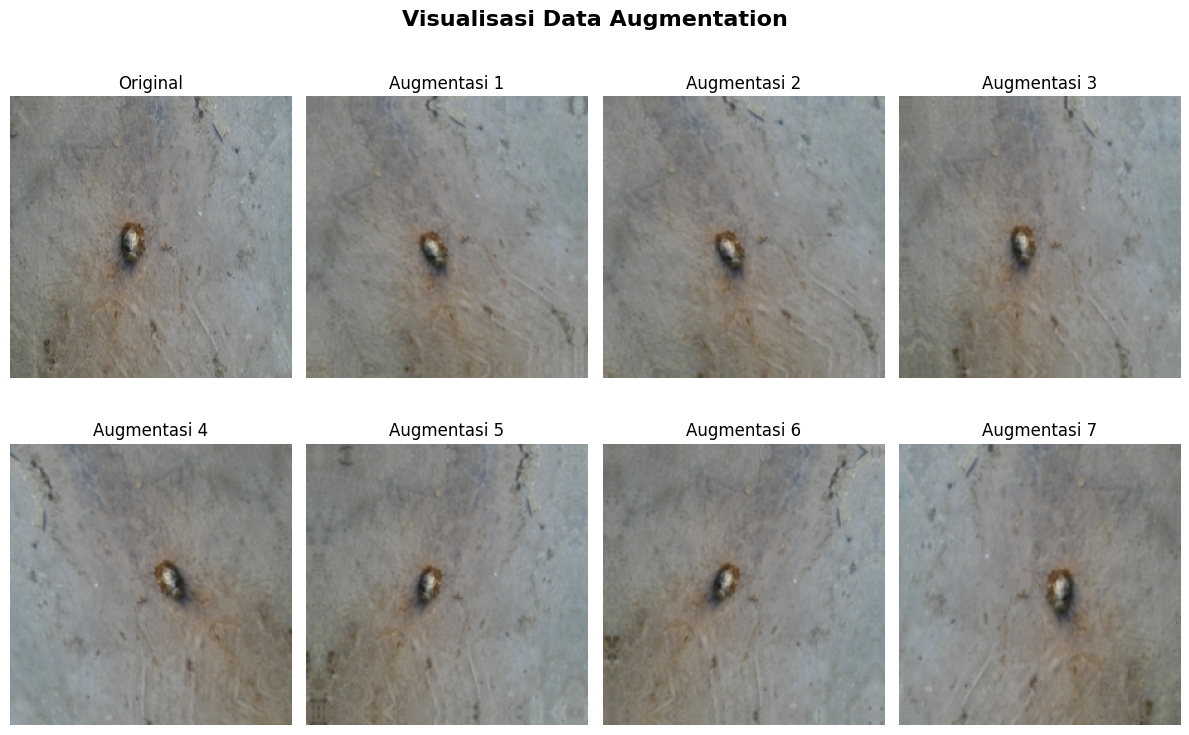

In [14]:
import matplotlib.pyplot as plt

# Ambil satu gambar dari training
images, labels = next(iter(train_ds))

sample_image = images[0]

plt.figure(figsize=(12, 8))

# Menampilkan gambar asli
plt.subplot(2, 4, 1)
plt.imshow(sample_image)
plt.title("Original")
plt.axis("off")

# Menampilkan 7 hasil augmentasi
for i in range(7):

    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )

    plt.subplot(2, 4, i + 2)

    plt.imshow(
        tf.clip_by_value(
            augmented_image[0], 0.0, 1.0
        )
    )

    plt.title(f"Augmentasi {i + 1}")
    plt.axis("off")

plt.suptitle(
    "Visualisasi Data Augmentation",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [15]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Membangun model CNN
model = models.Sequential([

    # Input gambar
    layers.Input(shape=(224, 224, 3)),

    # Augmentasi hanya saat training
    data_augmentation,

    # Convolution Block 1
    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 4
    layers.Conv2D(
        256, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Classification Layer
    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    # Mengurangi risiko overfitting
    layers.Dropout(0.3),

    # Output 4 kelas
    layers.Dense(
        len(class_names),
        activation="softmax"
    )

])

# Menampilkan arsitektur CNN
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,828 (1.61 MB)

 Trainable params: 421,828 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Konfigurasi training
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("Model CNN berhasil dikonfigurasi!")
print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Loss: Sparse Categorical Crossentropy")
print("Metrics: Accuracy")

Model CNN berhasil dikonfigurasi!
Optimizer: Adam
Learning Rate: 0.001
Loss: Sparse Categorical Crossentropy
Metrics: Accuracy


In [17]:
# Callback untuk menghentikan training
# apabila validation loss tidak membaik

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Menyimpan model terbaik
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/content/best_cnn_baseline.keras",
    monitor="val_loss",
    save_best_only=True
)

# Memulai training
history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=30,

    callbacks=[
        early_stopping,
        checkpoint
    ]

)

Epoch 1/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 20s 76ms/step - accuracy: 0.6065 - loss: 0.9373 - val_accuracy: 0.7337 - val_loss: 0.7139
Epoch 2/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 14s 71ms/step - accuracy: 0.7388 - loss: 0.7468 - val_accuracy: 0.7551 - val_loss: 0.6547
Epoch 3/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 16s 78ms/step - accuracy: 0.7617 - loss: 0.6794 - val_accuracy: 0.7877 - val_loss: 0.6084
Epoch 4/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 14s 72ms/step - accuracy: 0.7709 - loss: 0.6423 - val_accuracy: 0.7928 - val_loss: 0.5616
Epoch 5/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 68ms/step - accuracy: 0.7810 - loss: 0.6106 - val_accuracy: 0.8091 - val_loss: 0.5544
Epoch 6/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 69ms/step - accuracy: 0.7941 - loss: 0.5736 - val_accuracy: 0.8236 - val_loss: 0.5121
Epoch 7/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 68ms/step - accuracy: 0.8040 - loss: 0.5476 - val_accuracy: 0.8262 - val_loss: 0.4833
Epoch 8/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 67ms/step - accuracy: 0.7979 - loss: 0.5487 - 

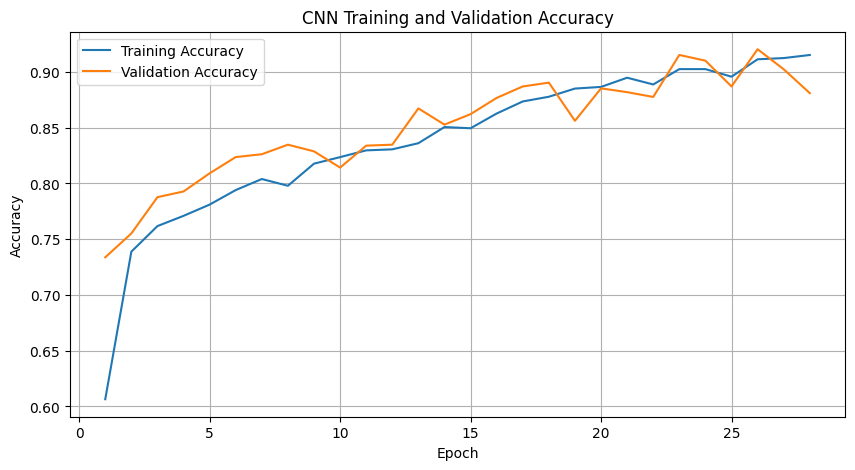

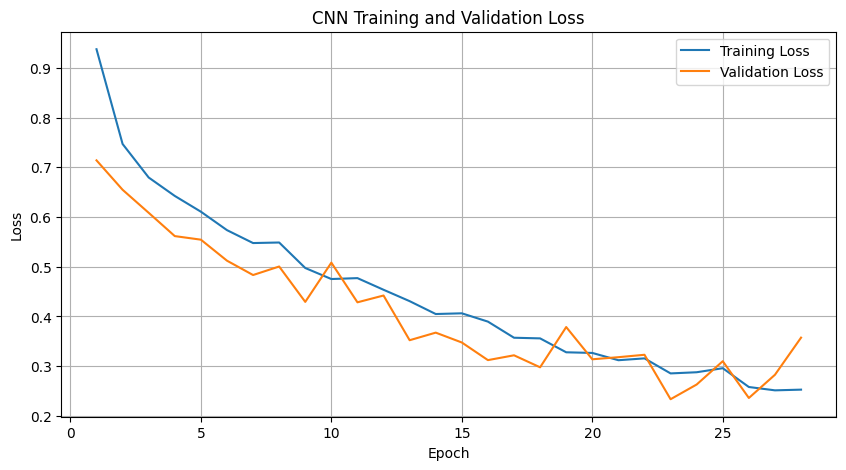

=== HASIL TRAINING CNN ===
Total epoch: 28
Epoch terbaik: 23
Validation Accuracy pada epoch terbaik: 91.52 %
Validation Loss terbaik: 0.2336


In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Riwayat training
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = range(1, len(acc) + 1)

# Grafik Accuracy
plt.figure(figsize=(10, 5))

plt.plot(epochs, acc, label="Training Accuracy")
plt.plot(epochs, val_acc, label="Validation Accuracy")

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Grafik Loss
plt.figure(figsize=(10, 5))

plt.plot(epochs, loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# Epoch terbaik berdasarkan validation loss
best_epoch = np.argmin(val_loss) + 1

print("=== HASIL TRAINING CNN ===")
print("Total epoch:", len(acc))
print("Epoch terbaik:", best_epoch)

print("Validation Accuracy pada epoch terbaik:",
      round(val_acc[best_epoch - 1] * 100, 2), "%")

print("Validation Loss terbaik:",
      round(val_loss[best_epoch - 1], 4))

In [19]:
import os

model_path = "/content/best_cnn_baseline.keras"

if os.path.exists(model_path):
    print("Model CNN terbaik berhasil disimpan!")
    print("Lokasi:", model_path)
else:
    print("File model belum ditemukan.")

Model CNN terbaik berhasil disimpan!
Lokasi: /content/best_cnn_baseline.keras


In [20]:
import tensorflow as tf
import numpy as np

# Load model terbaik
best_model = tf.keras.models.load_model(
    "/content/best_cnn_baseline.keras"
)

# Evaluasi pada validation dataset
val_loss, val_accuracy = best_model.evaluate(
    val_ds,
    verbose=1
)

print("\n=== EVALUASI CNN BASELINE ===")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")

37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.9152 - loss: 0.2336

=== EVALUASI CNN BASELINE ===
Validation Accuracy: 91.52%
Validation Loss: 0.2336


In [21]:
from sklearn.metrics import classification_report
import numpy as np
import pandas as pd

# Prediksi data validation
y_prob = best_model.predict(val_ds)

# Ambil kelas dengan probabilitas tertinggi
y_pred = np.argmax(y_prob, axis=1)

# Ambil label sebenarnya dari validation dataset
y_true = np.concatenate([
    y.numpy() for _, y in val_ds
])

print("=== CLASSIFICATION REPORT ===")

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step
=== CLASSIFICATION REPORT ===
                    precision    recall  f1-score   support

       Coccidiosis     0.9579    0.9715    0.9646       351
           Healthy     0.9107    0.8778    0.8939       360
New Castle Disease     0.9143    0.7529    0.8258        85
        Salmonella     0.8810    0.9355    0.9074       372

          accuracy                         0.9152      1168
         macro avg     0.9160    0.8844    0.8979      1168
      weighted avg     0.9157    0.9152    0.9145      1168



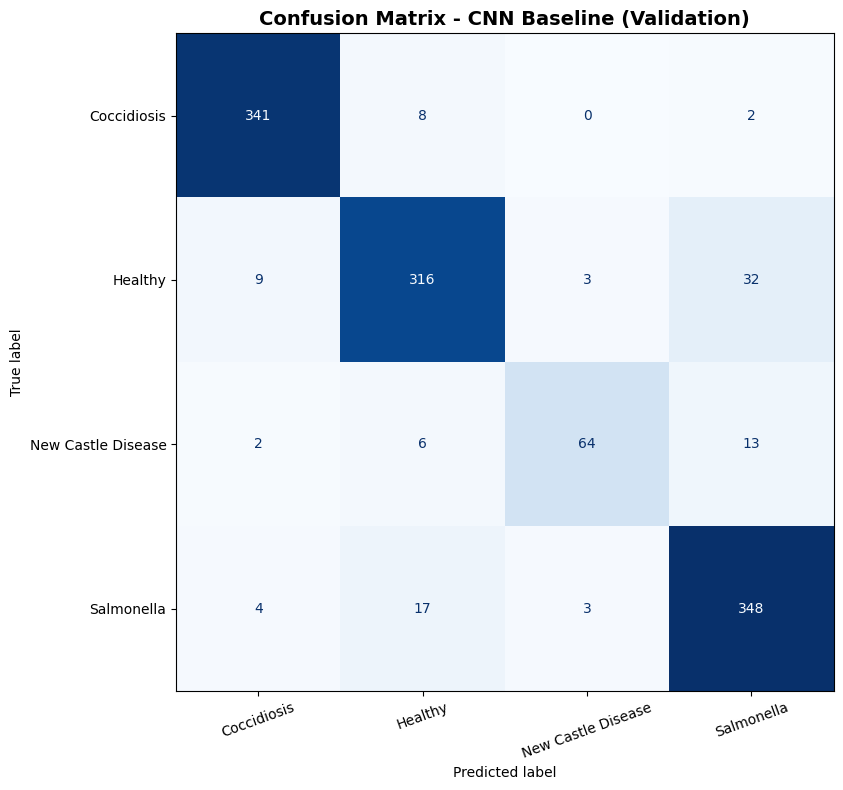

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# Hitung confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

# Visualisasi
fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    xticks_rotation=20,
    colorbar=False
)

plt.title(
    "Confusion Matrix - CNN Baseline (Validation)",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "/content/confusion_matrix_baseline.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Mengubah label training menjadi angka
y_train = train_df["label"].map(class_to_index).to_numpy()

# Menghitung bobot berdasarkan data training saja
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=y_train
)

class_weights = {
    int(i): float(w)
    for i, w in enumerate(weights)
}

print("=== CLASS WEIGHTS ===")
for i, name in enumerate(class_names):
    print(f"{name}: {class_weights[i]:.4f}")

=== CLASS WEIGHTS ===
Coccidiosis: 0.8310
Healthy: 0.8112
New Castle Disease: 3.4656
Salmonella: 0.7841


In [24]:
import tensorflow as tf

# Memuat arsitektur baseline
best_model = tf.keras.models.load_model(
    "/content/best_cnn_baseline.keras"
)

# Menetapkan random seed
tf.keras.utils.set_random_seed(42)

# Membuat model baru dengan arsitektur sama
# tetapi bobot awal baru
weighted_model = tf.keras.models.clone_model(best_model)

# Compile model
weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN Class Weighting berhasil dibuat!")
weighted_model.summary()

CNN Class Weighting berhasil dibuat!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,828 (1.61 MB)

 Trainable params: 421,828 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# Early stopping
early_stopping_weighted = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Simpan model terbaik
checkpoint_weighted = tf.keras.callbacks.ModelCheckpoint(
    "/content/best_cnn_weighted.keras",
    monitor="val_loss",
    save_best_only=True
)

# Training dengan class weighting
history_weighted = weighted_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weights,
    callbacks=[
        early_stopping_weighted,
        checkpoint_weighted
    ]
)

Epoch 1/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 15s 73ms/step - accuracy: 0.8658 - loss: 0.3947 - val_accuracy: 0.8947 - val_loss: 0.2813
Epoch 2/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.8638 - loss: 0.3935 - val_accuracy: 0.8844 - val_loss: 0.3519
Epoch 3/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 20s 69ms/step - accuracy: 0.8673 - loss: 0.3721 - val_accuracy: 0.9015 - val_loss: 0.2746
Epoch 4/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 72ms/step - accuracy: 0.8897 - loss: 0.3236 - val_accuracy: 0.8853 - val_loss: 0.2877
Epoch 5/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 69ms/step - accuracy: 0.8866 - loss: 0.3228 - val_accuracy: 0.8801 - val_loss: 0.3231
Epoch 6/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 71ms/step - accuracy: 0.8792 - loss: 0.3339 - val_accuracy: 0.9041 - val_loss: 0.2681
Epoch 7/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 68ms/step - accuracy: 0.8853 - loss: 0.3239 - val_accuracy: 0.8836 - val_loss: 0.2928
Epoch 8/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 69ms/step - accuracy: 0.8856 - loss: 0.3158 - 

In [27]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score
)
import pandas as pd
import numpy as np

# Load model terbaik
baseline = tf.keras.models.load_model(
    "/content/best_cnn_baseline.keras"
)

weighted = tf.keras.models.load_model(
    "/content/best_cnn_weighted.keras"
)

# Label validation sebenarnya
y_true = val_df["label"].map(
    class_to_index
).to_numpy()

# Prediksi kedua model
pred_baseline = np.argmax(
    baseline.predict(val_ds), axis=1
)

pred_weighted = np.argmax(
    weighted.predict(val_ds), axis=1
)

# Membandingkan metrik
comparison = pd.DataFrame({
    "Model": ["CNN Baseline", "CNN + Class Weight"],
    "Accuracy": [
        accuracy_score(y_true, pred_baseline),
        accuracy_score(y_true, pred_weighted)
    ],
    "Macro F1": [
        f1_score(y_true, pred_baseline, average="macro"),
        f1_score(y_true, pred_weighted, average="macro")
    ]
})

print("=== PERBANDINGAN MODEL ===")
display(comparison.round(4))

print("\n=== CNN BASELINE ===")
print(classification_report(
    y_true, pred_baseline,
    labels=range(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("\n=== CNN CLASS WEIGHTING ===")
print(classification_report(
    y_true, pred_weighted,
    labels=range(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step
=== PERBANDINGAN MODEL ===


,Model,Accuracy,Macro F1
0,CNN Baseline,0.9152,0.8979
1,CNN + Class Weight,0.9041,0.8870



=== CNN BASELINE ===
                    precision    recall  f1-score   support

       Coccidiosis     0.9579    0.9715    0.9646       351
           Healthy     0.9107    0.8778    0.8939       360
New Castle Disease     0.9143    0.7529    0.8258        85
        Salmonella     0.8810    0.9355    0.9074       372

          accuracy                         0.9152      1168
         macro avg     0.9160    0.8844    0.8979      1168
      weighted avg     0.9157    0.9152    0.9145      1168


=== CNN CLASS WEIGHTING ===
                    precision    recall  f1-score   support

       Coccidiosis     0.9317    0.9715    0.9512       351
           Healthy     0.8825    0.8972    0.8898       360
New Castle Disease     0.8046    0.8235    0.8140        85
        Salmonella     0.9226    0.8656    0.8932       372

          accuracy                         0.9041      1168
         macro avg     0.8854    0.8895    0.8870      1168
      weighted avg     0.9044    0.9041    0

In [28]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Mengubah label training menjadi angka
y_train = train_df["label"].map(class_to_index).to_numpy()

# Menghitung bobot berdasarkan data training saja
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=y_train
)

class_weights = {
    int(i): float(w)
    for i, w in enumerate(weights)
}

print("=== CLASS WEIGHTS ===")
for i, name in enumerate(class_names):
    print(f"{name}: {class_weights[i]:.4f}")

=== CLASS WEIGHTS ===
Coccidiosis: 0.8310
Healthy: 0.8112
New Castle Disease: 3.4656
Salmonella: 0.7841


In [29]:
import tensorflow as tf

# Memuat arsitektur baseline
best_model = tf.keras.models.load_model(
    "/content/best_cnn_baseline.keras"
)

# Menetapkan random seed
tf.keras.utils.set_random_seed(42)

# Membuat model baru dengan arsitektur sama
# tetapi bobot awal baru
weighted_model = tf.keras.models.clone_model(best_model)

# Compile model
weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN Class Weighting berhasil dibuat!")
weighted_model.summary()

CNN Class Weighting berhasil dibuat!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,828 (1.61 MB)

 Trainable params: 421,828 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [30]:
# Early stopping
early_stopping_weighted = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Simpan model terbaik
checkpoint_weighted = tf.keras.callbacks.ModelCheckpoint(
    "/content/best_cnn_weighted.keras",
    monitor="val_loss",
    save_best_only=True
)

# Training dengan class weighting
history_weighted = weighted_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weights,
    callbacks=[
        early_stopping_weighted,
        checkpoint_weighted
    ]
)

Epoch 1/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 19s 73ms/step - accuracy: 0.5406 - loss: 1.1326 - val_accuracy: 0.6704 - val_loss: 0.9404
Epoch 2/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.6678 - loss: 0.9778 - val_accuracy: 0.7440 - val_loss: 0.7043
Epoch 3/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 14s 72ms/step - accuracy: 0.7047 - loss: 0.9002 - val_accuracy: 0.7432 - val_loss: 0.6820
Epoch 4/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 68ms/step - accuracy: 0.6927 - loss: 0.8601 - val_accuracy: 0.6438 - val_loss: 0.9327
Epoch 5/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 14s 74ms/step - accuracy: 0.7151 - loss: 0.8204 - val_accuracy: 0.4281 - val_loss: 1.7985
Epoch 6/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 68ms/step - accuracy: 0.7028 - loss: 0.8526 - val_accuracy: 0.7406 - val_loss: 0.6831
Epoch 7/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 69ms/step - accuracy: 0.7208 - loss: 0.7684 - val_accuracy: 0.7260 - val_loss: 0.6656
Epoch 8/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 22s 71ms/step - accuracy: 0.7283 - loss: 0.7385 - 

In [31]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score
)
import pandas as pd
import numpy as np

# Load model terbaik
baseline = tf.keras.models.load_model(
    "/content/best_cnn_baseline.keras"
)

weighted = tf.keras.models.load_model(
    "/content/best_cnn_weighted.keras"
)

# Label validation sebenarnya
y_true = val_df["label"].map(
    class_to_index
).to_numpy()

# Prediksi kedua model
pred_baseline = np.argmax(
    baseline.predict(val_ds), axis=1
)

pred_weighted = np.argmax(
    weighted.predict(val_ds), axis=1
)

# Membandingkan metrik
comparison = pd.DataFrame({
    "Model": ["CNN Baseline", "CNN + Class Weight"],
    "Accuracy": [
        accuracy_score(y_true, pred_baseline),
        accuracy_score(y_true, pred_weighted)
    ],
    "Macro F1": [
        f1_score(y_true, pred_baseline, average="macro"),
        f1_score(y_true, pred_weighted, average="macro")
    ]
})

print("=== PERBANDINGAN MODEL ===")
display(comparison.round(4))

print("\n=== CNN BASELINE ===")
print(classification_report(
    y_true, pred_baseline,
    labels=range(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("\n=== CNN CLASS WEIGHTING ===")
print(classification_report(
    y_true, pred_weighted,
    labels=range(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step
=== PERBANDINGAN MODEL ===


,Model,Accuracy,Macro F1
0,CNN Baseline,0.9152,0.8979
1,CNN + Class Weight,0.9127,0.8985



=== CNN BASELINE ===
                    precision    recall  f1-score   support

       Coccidiosis     0.9579    0.9715    0.9646       351
           Healthy     0.9107    0.8778    0.8939       360
New Castle Disease     0.9143    0.7529    0.8258        85
        Salmonella     0.8810    0.9355    0.9074       372

          accuracy                         0.9152      1168
         macro avg     0.9160    0.8844    0.8979      1168
      weighted avg     0.9157    0.9152    0.9145      1168


=== CNN CLASS WEIGHTING ===
                    precision    recall  f1-score   support

       Coccidiosis     0.9469    0.9658    0.9563       351
           Healthy     0.8880    0.9250    0.9061       360
New Castle Disease     0.8276    0.8471    0.8372        85
        Salmonella     0.9253    0.8656    0.8944       372

          accuracy                         0.9127      1168
         macro avg     0.8970    0.9009    0.8985      1168
      weighted avg     0.9132    0.9127    0

In [32]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load CNN Baseline terbaik
gradcam_base = tf.keras.models.load_model(
    "/content/best_cnn_baseline.keras"
)

# Membuat model untuk mengambil feature map
inputs = tf.keras.Input(shape=(224, 224, 3))
x = inputs
last_conv_output = None

for layer in gradcam_base.layers:

    if isinstance(
        layer,
        (tf.keras.Sequential, tf.keras.layers.Dropout)
    ):
        x = layer(x, training=False)
    else:
        x = layer(x)

    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_output = x

if last_conv_output is None:
    raise ValueError("Conv2D tidak ditemukan!")

gradcam_model = tf.keras.Model(
    inputs=inputs,
    outputs=[last_conv_output, x]
)

print("Model Grad-CAM berhasil dibuat!")
print("Feature map:", last_conv_output.shape)

Model Grad-CAM berhasil dibuat!
Feature map: (None, 28, 28, 256)


In [33]:
def generate_gradcam(image_array):

    image_batch = tf.expand_dims(
        image_array, axis=0
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = gradcam_model(
            image_batch,
            training=False
        )

        class_index = int(
            tf.argmax(predictions[0]).numpy()
        )

        class_score = predictions[:, class_index]

    # Menghitung gradien
    grads = tape.gradient(
        class_score,
        conv_outputs
    )

    if grads is None:
        raise ValueError("Gradien tidak ditemukan!")

    # Bobot gradien tiap channel
    weights = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Membuat heatmap
    heatmap = tf.reduce_sum(
        conv_outputs[0] * weights,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = tf.math.divide_no_nan(
        heatmap,
        tf.reduce_max(heatmap)
    )

    return (
        heatmap.numpy(),
        class_index,
        float(predictions[0, class_index])
    )

print("Fungsi Grad-CAM siap digunakan!")

Fungsi Grad-CAM siap digunakan!


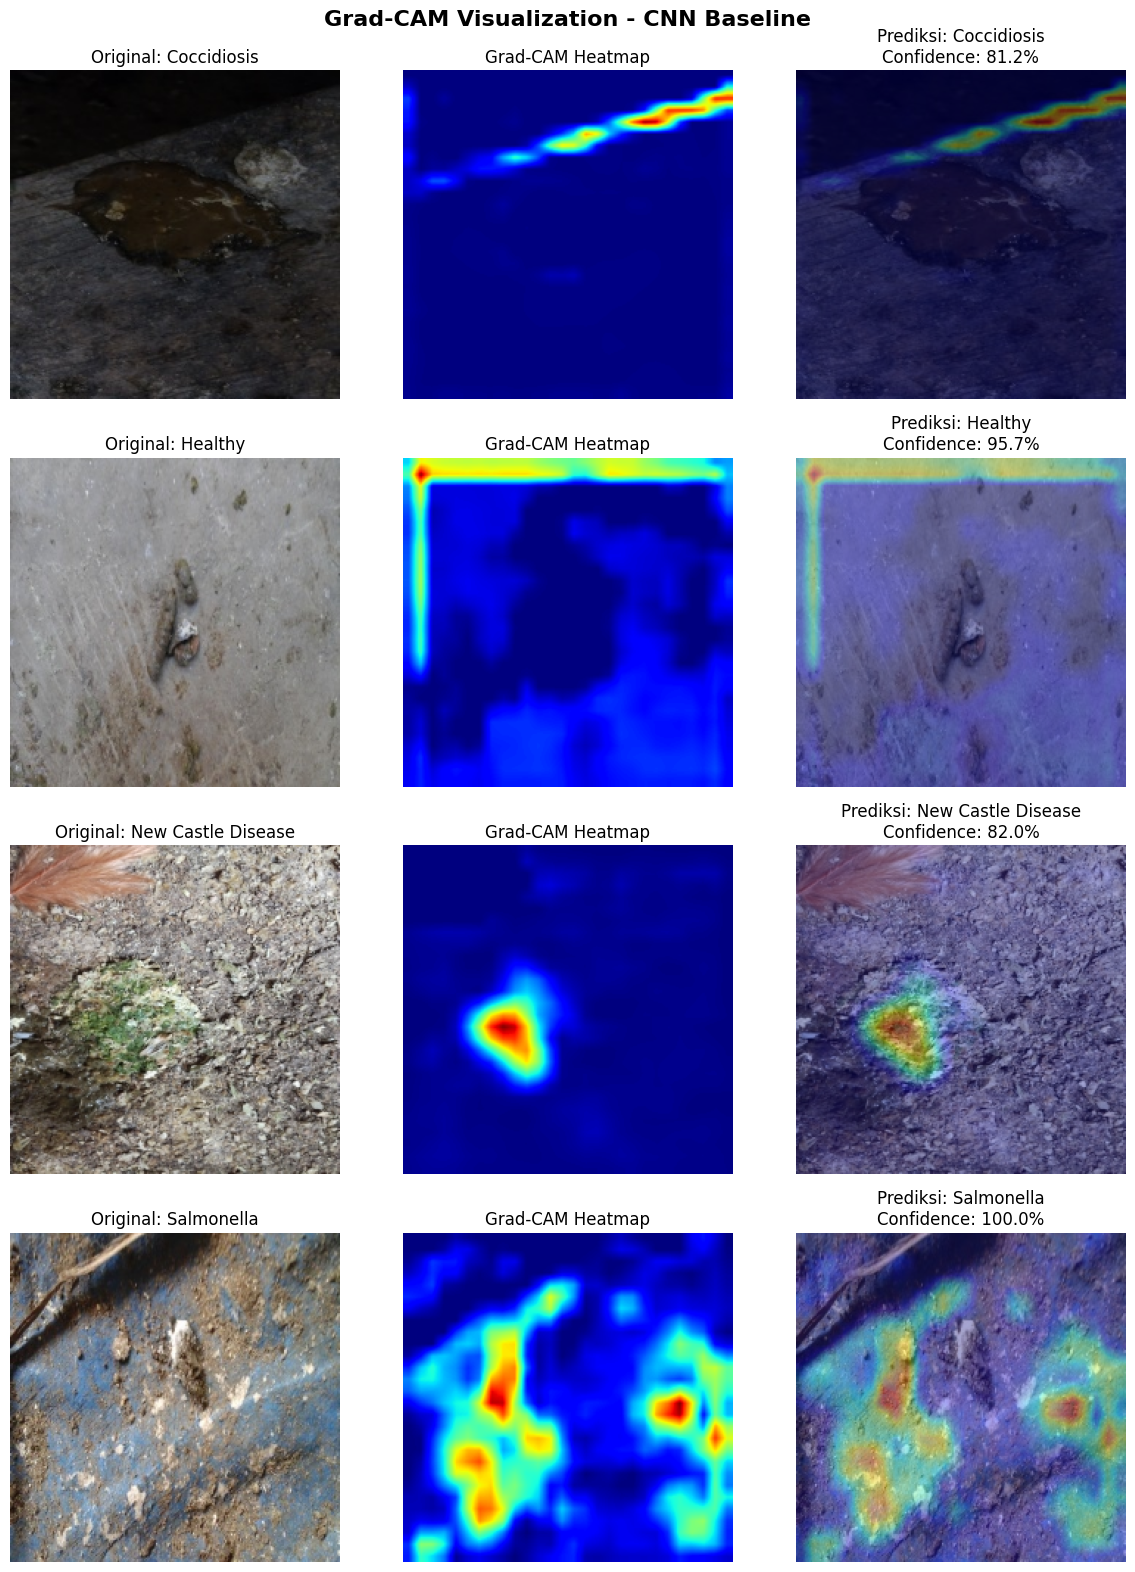

In [34]:
from pathlib import Path

train_dir = Path("/content/chicken_dataset/Train")

# Satu gambar dari setiap kelas
samples = (
    val_df.groupby("label", group_keys=False)
    .sample(n=1, random_state=42)
)

fig, axes = plt.subplots(
    len(samples), 3,
    figsize=(12, 4 * len(samples))
)

for i, (_, row) in enumerate(samples.iterrows()):

    img_path = train_dir / row["images"]

    # Load dan normalisasi gambar
    img = tf.keras.utils.load_img(
        img_path,
        target_size=(224, 224)
    )

    img_array = (
        tf.keras.utils.img_to_array(img) / 255.0
    )

    # Grad-CAM
    heatmap, pred_index, confidence = (
        generate_gradcam(img_array)
    )

    # Perbesar heatmap ke 224x224
    heatmap = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy()[..., 0]

    # Membuat overlay
    colored_heatmap = plt.get_cmap("jet")(
        heatmap
    )[..., :3]

    overlay = np.clip(
        0.65 * img_array +
        0.35 * colored_heatmap,
        0, 1
    )

    # Original
    axes[i, 0].imshow(img_array)
    axes[i, 0].set_title(
        f"Original: {row['label']}"
    )

    # Heatmap
    axes[i, 1].imshow(
        heatmap, cmap="jet",
        vmin=0, vmax=1
    )
    axes[i, 1].set_title("Grad-CAM Heatmap")

    # Overlay
    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title(
        f"Prediksi: {class_names[pred_index]}\n"
        f"Confidence: {confidence:.1%}"
    )

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle(
    "Grad-CAM Visualization - CNN Baseline",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "/content/gradcam_baseline_4kelas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
import tensorflow as tf
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Memuat kedua model terbaik
baseline_model = tf.keras.models.load_model(
    "/content/best_cnn_baseline.keras"
)

weighted_model = tf.keras.models.load_model(
    "/content/best_cnn_weighted.keras"
)

# Label sebenarnya dari data testing
y_test = test_df["label"].map(
    class_to_index
).to_numpy()

# Prediksi model baseline
baseline_prob = baseline_model.predict(test_ds)
baseline_pred = np.argmax(baseline_prob, axis=1)

# Prediksi model class weighting
weighted_prob = weighted_model.predict(test_ds)
weighted_pred = np.argmax(weighted_prob, axis=1)

# Fungsi evaluasi
def evaluate_predictions(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision Macro": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall Macro": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "F1 Macro": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        )
    }

# Membuat tabel perbandingan
results = pd.DataFrame([
    evaluate_predictions(
        "CNN Baseline", y_test, baseline_pred
    ),
    evaluate_predictions(
        "CNN Class Weighting", y_test, weighted_pred
    )
])

print("=== HASIL EVALUASI DATA TESTING ===")
display(results.round(4))

print("\n=== CLASSIFICATION REPORT BASELINE ===")
print(classification_report(
    y_test,
    baseline_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("\n=== CLASSIFICATION REPORT CLASS WEIGHTING ===")
print(classification_report(
    y_test,
    weighted_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step
=== HASIL EVALUASI DATA TESTING ===


,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,CNN Baseline,0.9024,0.8852,0.8756,0.8801
1,CNN Class Weighting,0.8947,0.8656,0.8950,0.8776



=== CLASSIFICATION REPORT BASELINE ===
                    precision    recall  f1-score   support

       Coccidiosis     0.9564    0.9347    0.9454       352
           Healthy     0.8822    0.8944    0.8883       360
New Castle Disease     0.8101    0.7619    0.7853        84
        Salmonella     0.8921    0.9113    0.9016       372

          accuracy                         0.9024      1168
         macro avg     0.8852    0.8756    0.8801      1168
      weighted avg     0.9025    0.9024    0.9023      1168


=== CLASSIFICATION REPORT CLASS WEIGHTING ===
                    precision    recall  f1-score   support

       Coccidiosis     0.9222    0.9432    0.9326       352
           Healthy     0.8828    0.9000    0.8913       360
New Castle Disease     0.7282    0.8929    0.8021        84
        Salmonella     0.9290    0.8441    0.8845       372

          accuracy                         0.8947      1168
         macro avg     0.8656    0.8950    0.8776      1168
      we

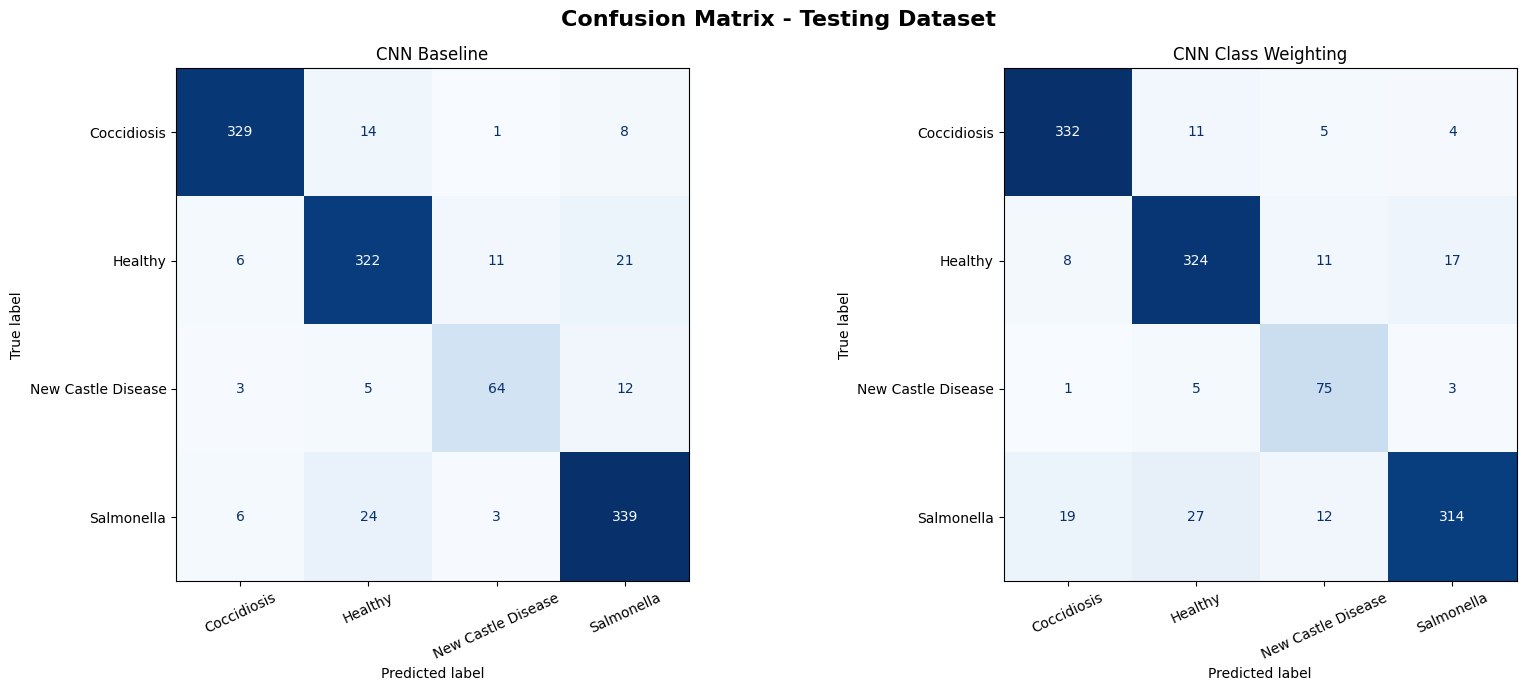

In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

predictions = [
    ("CNN Baseline", baseline_pred),
    ("CNN Class Weighting", weighted_pred)
]

for ax, (name, y_pred) in zip(axes, predictions):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=range(len(class_names))
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        xticks_rotation=25,
        colorbar=False
    )

    ax.set_title(name)

plt.suptitle(
    "Confusion Matrix - Testing Dataset",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "/content/confusion_matrix_testing.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

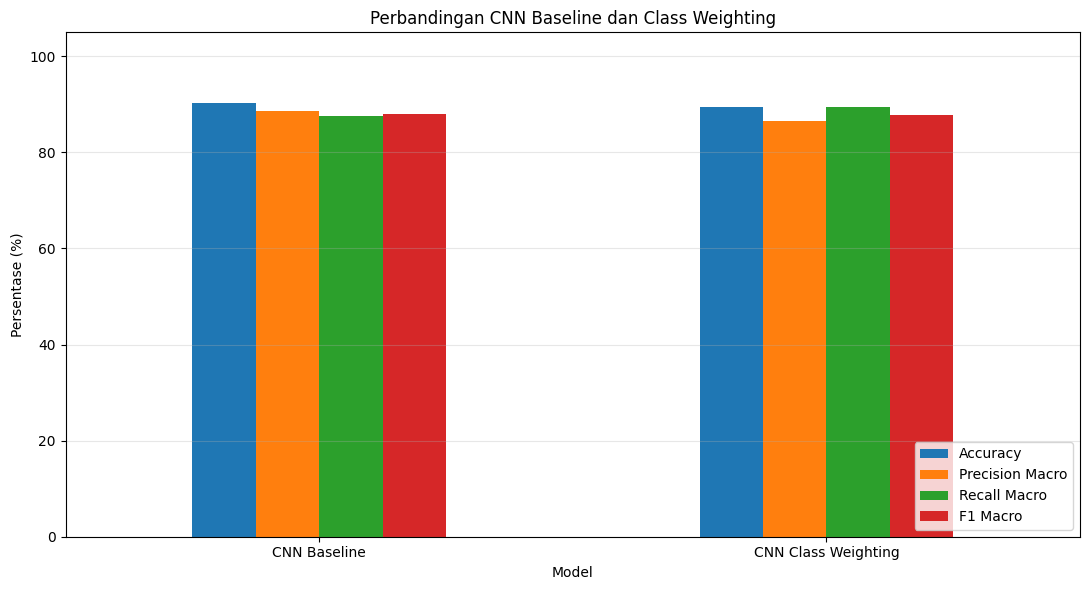

Tabel dan grafik berhasil disimpan!


In [37]:
import os
import matplotlib.pyplot as plt

output_dir = "/content/hasil_proyek_cnn"
os.makedirs(output_dir, exist_ok=True)

# Simpan tabel hasil testing
results.to_csv(
    f"{output_dir}/hasil_evaluasi_testing.csv",
    index=False
)

# Grafik perbandingan
ax = results.set_index("Model")[
    ["Accuracy", "Precision Macro",
     "Recall Macro", "F1 Macro"]
].mul(100).plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

plt.title("Perbandingan CNN Baseline dan Class Weighting")
plt.ylabel("Persentase (%)")
plt.ylim(0, 105)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{output_dir}/perbandingan_model.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Tabel dan grafik berhasil disimpan!")

In [38]:
import shutil
import zipfile
from pathlib import Path

output_dir = Path("/content/hasil_proyek_cnn")

# File hasil eksperimen
file_paths = [
    "/content/best_cnn_baseline.keras",
    "/content/best_cnn_weighted.keras",
    "/content/confusion_matrix_testing.png",
    "/content/gradcam_baseline_4kelas.png",
    "/content/chicken_dataset/train_data_clean.csv",
    "/content/chicken_dataset/splits/train.csv",
    "/content/chicken_dataset/splits/validation.csv",
    "/content/chicken_dataset/splits/test.csv"
]

# Salin file yang tersedia
for file_path in file_paths:
    source = Path(file_path)

    if source.exists():
        shutil.copy2(
            source,
            output_dir / source.name
        )
        print("Tersimpan:", source.name)
    else:
        print("Belum ditemukan:", source.name)

# Buat ZIP
zip_path = "/content/hasil_proyek_cnn.zip"

with zipfile.ZipFile(
    zip_path, "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for file in output_dir.iterdir():
        if file.is_file():
            zipf.write(file, arcname=file.name)

print("\nZIP berhasil dibuat:", zip_path)

Tersimpan: best_cnn_baseline.keras
Tersimpan: best_cnn_weighted.keras
Tersimpan: confusion_matrix_testing.png
Tersimpan: gradcam_baseline_4kelas.png
Tersimpan: train_data_clean.csv
Tersimpan: train.csv
Tersimpan: validation.csv
Tersimpan: test.csv

ZIP berhasil dibuat: /content/hasil_proyek_cnn.zip


In [39]:
from google.colab import files

files.download("/content/hasil_proyek_cnn.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>